# Q6 Practice: 动量与趋势过滤 + RiskParity

本 notebook 延续 Q3/Q5 复盘框架，基准策略固定为原三资产 RiskParity：

- `510300.SS`: 沪深300 ETF
- `513100.SS`: 纳指100 ETF
- `518880.SS`: 黄金 ETF

研究重点不是寻找历史收益最高的参数，而是判断动量过滤、趋势过滤和 RiskParity 叠加后，是否让策略更稳健、更可解释、更可能复现。


## 1. Setup and Data Loading

统一使用 Q3 复盘确认过的十年样本窗口：`2016-06-21` 起，到当前可取得的共同交易日。所有策略使用相同资产池、相同交易日、相同 10 个交易日再平衡频率，并且权重在信号日之后一个交易日才生效，避免同日收盘信号的前视偏差。


In [ ]:
# Keep relative research paths stable after this notebook moved.
import os
from xquant.project import find_repo_root

REPO_ROOT = find_repo_root()
os.chdir(REPO_ROOT)


In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

warnings.filterwarnings("ignore")

plt.rcParams["font.sans-serif"] = ["Arial Unicode MS", "SimHei", "STHeiti"]
plt.rcParams["axes.unicode_minus"] = False

OUTPUT_DIR = Path("outputs/q6-momentum-trend-riskparity")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SYMBOLS = ("510300.SS", "513100.SS", "518880.SS")
SYMBOL_NAMES = {
    "510300.SS": "沪深300ETF",
    "513100.SS": "纳指100ETF",
    "518880.SS": "黄金ETF",
}
START = "2016-06-21"
END = pd.Timestamp.today().strftime("%Y-%m-%d")
INITIAL_CAPITAL = 100_000
REBALANCE_DAYS = 10
BASE_VOL_WINDOW = 20
BASE_MOM_LOOKBACK = 126
BASE_TOP_N = 2
BASE_TREND_MA = 200
BASE_ST_ATR = 10
BASE_ST_MULTIPLIER = 3.0
TRADING_DAYS = 252


In [2]:
def _flatten_yfinance_columns(df, symbol):
    out = df.copy()
    if isinstance(out.columns, pd.MultiIndex):
        out.columns = [col[0] if col[1] == symbol else "_".join(map(str, col)).strip() for col in out.columns]
    out.columns = [str(c).lower().replace(" ", "_") for c in out.columns]
    return out


def download_symbol(symbol, start=START, end=None):
    # yfinance end is exclusive. Passing None lets Yahoo return the latest available bar.
    df = yf.download(symbol, start=start, end=end, auto_adjust=True, progress=False, threads=False)
    if df.empty:
        raise RuntimeError(f"No data downloaded for {symbol}")
    df = _flatten_yfinance_columns(df, symbol)
    required = ["open", "high", "low", "close", "volume"]
    missing = [c for c in required if c not in df.columns]
    if missing:
        raise RuntimeError(f"{symbol} missing columns: {missing}")
    df = df[required].dropna(subset=["open", "high", "low", "close"])
    df.index = pd.DatetimeIndex(df.index).tz_localize(None)
    return df

raw_data = {sym: download_symbol(sym, START) for sym in SYMBOLS}
common_index = raw_data[SYMBOLS[0]].index
for sym in SYMBOLS[1:]:
    common_index = common_index.intersection(raw_data[sym].index)
common_index = common_index.sort_values()

data = {sym: raw_data[sym].reindex(common_index).dropna(subset=["close"]) for sym in SYMBOLS}
close = pd.DataFrame({sym: data[sym]["close"] for sym in SYMBOLS}).dropna()
high = pd.DataFrame({sym: data[sym]["high"] for sym in SYMBOLS}).reindex(close.index)
low = pd.DataFrame({sym: data[sym]["low"] for sym in SYMBOLS}).reindex(close.index)
open_ = pd.DataFrame({sym: data[sym]["open"] for sym in SYMBOLS}).reindex(close.index)
returns = close.pct_change().fillna(0.0)

print(f"共同样本: {close.index[0].date()} 到 {close.index[-1].date()}，{len(close)} 个交易日")
for sym in SYMBOLS:
    print(f"{SYMBOL_NAMES[sym]}: {close[sym].iloc[-1] / close[sym].iloc[0] - 1:.2%}")


共同样本: 2016-06-21 到 2026-06-22，2425 个交易日
沪深300ETF: 94.85%
纳指100ETF: 627.68%
黄金ETF: 221.39%


## 2. Backtest and Metric Helpers

策略统一用“过滤器先决定可投资资产，再决定权重”的结构。被过滤掉的资金进入现金，现金日收益按 0 处理。这样可以看出择时过滤是否真的减少回撤，而不是把风险偷偷转移到其他资产。


In [3]:
def rebalancing_dates(index, every=REBALANCE_DAYS):
    return pd.DatetimeIndex(index[::every])


def normalize_weights(w):
    weights = {sym: float(max(0.0, w.get(sym, 0.0))) for sym in SYMBOLS}
    total = sum(weights.values())
    if total > 1.0 + 1e-12:
        weights = {sym: val / total for sym, val in weights.items()}
        total = 1.0
    weights["CASH"] = max(0.0, 1.0 - total)
    return weights


def equal_weight(eligible):
    eligible = list(eligible)
    if not eligible:
        return normalize_weights({})
    return normalize_weights({sym: 1.0 / len(eligible) for sym in eligible})


def risk_parity_weight(date, eligible, vol_window=BASE_VOL_WINDOW):
    eligible = list(eligible)
    if not eligible:
        return normalize_weights({})
    loc = close.index.get_loc(date)
    if loc < vol_window:
        return normalize_weights({})
    hist = returns.iloc[loc - vol_window + 1 : loc + 1][eligible]
    vols = hist.std(ddof=1).replace(0, np.nan).dropna()
    vols = vols[vols > 0]
    if vols.empty:
        return normalize_weights({})
    inv = 1.0 / vols
    weights = (inv / inv.sum()).to_dict()
    return normalize_weights(weights)


def build_weights(name, selector, allocator, start_after=0):
    dates = rebalancing_dates(close.index)
    rows = []
    last = normalize_weights({})
    for date in close.index:
        if date in dates:
            eligible = selector(date)
            last = allocator(date, eligible)
        rows.append(last)
    weights = pd.DataFrame(rows, index=close.index).fillna(0.0)
    for col in list(SYMBOLS) + ["CASH"]:
        if col not in weights.columns:
            weights[col] = 0.0
    return weights[list(SYMBOLS) + ["CASH"]]


def backtest_from_weights(name, weights):
    asset_weights = weights[list(SYMBOLS)].shift(1).fillna(0.0)
    port_ret = (asset_weights * returns).sum(axis=1)
    nav = (1.0 + port_ret).cumprod() * INITIAL_CAPITAL
    nav.name = name
    return {"name": name, "weights": weights, "returns": port_ret, "nav": nav}


def run_strategy(name, selector, allocator):
    weights = build_weights(name, selector, allocator)
    return backtest_from_weights(name, weights)


def all_assets_selector(_date):
    return list(SYMBOLS)


def rp_allocator(vol_window=BASE_VOL_WINDOW):
    return lambda date, eligible: risk_parity_weight(date, eligible, vol_window=vol_window)


def ew_allocator(_date, eligible):
    return equal_weight(eligible)


In [4]:
momentum = close / close.shift(BASE_MOM_LOOKBACK) - 1.0
ma200 = close.rolling(BASE_TREND_MA).mean()


def momentum_selector(lookback=BASE_MOM_LOOKBACK, top_n=BASE_TOP_N, require_positive=True):
    mom = close / close.shift(lookback) - 1.0
    def _selector(date):
        row = mom.loc[date].dropna().sort_values(ascending=False)
        if require_positive:
            row = row[row > 0]
        return list(row.head(top_n).index)
    return _selector


def ma_trend_selector(ma_window=BASE_TREND_MA):
    ma = close.rolling(ma_window).mean()
    def _selector(date):
        row = (close.loc[date] > ma.loc[date]).dropna()
        return [sym for sym in SYMBOLS if bool(row.get(sym, False))]
    return _selector


def combine_selectors(*selectors):
    def _selector(date):
        sets = [set(sel(date)) for sel in selectors]
        if not sets:
            return []
        eligible = set.intersection(*sets)
        return [sym for sym in SYMBOLS if sym in eligible]
    return _selector


## 3. SuperTrend Indicator

当前数据源提供 High/Low/Close，所以可以实现 SuperTrend。这里使用经典 ATR SuperTrend：默认 ATR=10、倍数=3，只把价格在 SuperTrend 上方的资产视为可投资。


In [5]:
def true_range(high_s, low_s, close_s):
    prev_close = close_s.shift(1)
    parts = pd.concat([
        high_s - low_s,
        (high_s - prev_close).abs(),
        (low_s - prev_close).abs(),
    ], axis=1)
    return parts.max(axis=1)


def supertrend_signal_for_symbol(sym, atr_period=BASE_ST_ATR, multiplier=BASE_ST_MULTIPLIER):
    h = high[sym]
    l = low[sym]
    c = close[sym]
    atr = true_range(h, l, c).rolling(atr_period).mean()
    hl2 = (h + l) / 2.0
    basic_upper = hl2 + multiplier * atr
    basic_lower = hl2 - multiplier * atr

    final_upper = pd.Series(index=c.index, dtype=float)
    final_lower = pd.Series(index=c.index, dtype=float)
    st = pd.Series(index=c.index, dtype=float)
    bullish = pd.Series(False, index=c.index, dtype=bool)

    for i, date in enumerate(c.index):
        if pd.isna(atr.iloc[i]):
            continue
        if i == 0 or pd.isna(final_upper.iloc[i - 1]):
            final_upper.iloc[i] = basic_upper.iloc[i]
            final_lower.iloc[i] = basic_lower.iloc[i]
            st.iloc[i] = final_upper.iloc[i]
            bullish.iloc[i] = False
            continue

        prev_date = c.index[i - 1]
        final_upper.iloc[i] = basic_upper.iloc[i] if (basic_upper.iloc[i] < final_upper.iloc[i - 1] or c.loc[prev_date] > final_upper.iloc[i - 1]) else final_upper.iloc[i - 1]
        final_lower.iloc[i] = basic_lower.iloc[i] if (basic_lower.iloc[i] > final_lower.iloc[i - 1] or c.loc[prev_date] < final_lower.iloc[i - 1]) else final_lower.iloc[i - 1]

        if st.iloc[i - 1] == final_upper.iloc[i - 1]:
            st.iloc[i] = final_lower.iloc[i] if c.iloc[i] > final_upper.iloc[i] else final_upper.iloc[i]
        else:
            st.iloc[i] = final_upper.iloc[i] if c.iloc[i] < final_lower.iloc[i] else final_lower.iloc[i]
        bullish.iloc[i] = c.iloc[i] > st.iloc[i]
    return st, bullish


def supertrend_matrix(atr_period=BASE_ST_ATR, multiplier=BASE_ST_MULTIPLIER):
    signals = {}
    lines = {}
    for sym in SYMBOLS:
        line, bull = supertrend_signal_for_symbol(sym, atr_period, multiplier)
        lines[sym] = line
        signals[sym] = bull
    return pd.DataFrame(signals), pd.DataFrame(lines)

st_bullish, st_line = supertrend_matrix(BASE_ST_ATR, BASE_ST_MULTIPLIER)


def supertrend_selector(atr_period=BASE_ST_ATR, multiplier=BASE_ST_MULTIPLIER):
    bull, _line = supertrend_matrix(atr_period, multiplier)
    def _selector(date):
        row = bull.loc[date]
        return [sym for sym in SYMBOLS if bool(row.get(sym, False))]
    return _selector

print("SuperTrend 已计算：ATR=10, multiplier=3.0")


SuperTrend 已计算：ATR=10, multiplier=3.0


## 4. Baseline and Q6 Strategy Variants

策略分层如下：

1. 原三资产 RiskParity 基准
2. 动量过滤等权
3. 200 日均线趋势过滤等权
4. SuperTrend 过滤等权
5. 动量 + RiskParity
6. 200 日均线趋势过滤 + RiskParity
7. 动量 + 200 日均线趋势过滤 + RiskParity
8. SuperTrend + RiskParity，作为可实现的补充趋势过滤实验


In [6]:
strategies = {
    "原三资产RiskParity": run_strategy("原三资产RiskParity", all_assets_selector, rp_allocator(BASE_VOL_WINDOW)),
    "动量过滤等权": run_strategy("动量过滤等权", momentum_selector(BASE_MOM_LOOKBACK, BASE_TOP_N), ew_allocator),
    "MA200趋势过滤等权": run_strategy("MA200趋势过滤等权", ma_trend_selector(BASE_TREND_MA), ew_allocator),
    "SuperTrend过滤等权": run_strategy("SuperTrend过滤等权", supertrend_selector(BASE_ST_ATR, BASE_ST_MULTIPLIER), ew_allocator),
    "动量+RiskParity": run_strategy("动量+RiskParity", momentum_selector(BASE_MOM_LOOKBACK, BASE_TOP_N), rp_allocator(BASE_VOL_WINDOW)),
    "MA200趋势+RiskParity": run_strategy("MA200趋势+RiskParity", ma_trend_selector(BASE_TREND_MA), rp_allocator(BASE_VOL_WINDOW)),
    "动量+MA200趋势+RiskParity": run_strategy(
        "动量+MA200趋势+RiskParity",
        combine_selectors(momentum_selector(BASE_MOM_LOOKBACK, BASE_TOP_N), ma_trend_selector(BASE_TREND_MA)),
        rp_allocator(BASE_VOL_WINDOW),
    ),
    "SuperTrend+RiskParity": run_strategy("SuperTrend+RiskParity", supertrend_selector(BASE_ST_ATR, BASE_ST_MULTIPLIER), rp_allocator(BASE_VOL_WINDOW)),
}

nav = pd.DataFrame({name: item["nav"] for name, item in strategies.items()})
weights_by_strategy = {name: item["weights"] for name, item in strategies.items()}
portfolio_returns = pd.DataFrame({name: item["returns"] for name, item in strategies.items()})
benchmark_buy_hold = close.divide(close.iloc[0]).mean(axis=1) * INITIAL_CAPITAL
benchmark_buy_hold.name = "三资产等权买入持有"

print("策略运行完成")
print(nav.tail(1).T.rename(columns={nav.index[-1]: "期末净值"}))


策略运行完成
Date                            期末净值
原三资产RiskParity         418638.728899
动量过滤等权                 355596.224724
MA200趋势过滤等权            380223.035802
SuperTrend过滤等权         601035.135855
动量+RiskParity          366789.417472
MA200趋势+RiskParity     422559.142560
动量+MA200趋势+RiskParity  325438.158229
SuperTrend+RiskParity  614781.390807


## 5. Q3 Summary Table

Q3 指标保留：累计收益、年化收益、年化波动、最大回撤、Sharpe、Calmar、当前权重、平均权重。


In [7]:
def drawdown(nav_s):
    return nav_s / nav_s.cummax() - 1.0


def strategy_metrics(nav_s, ret_s):
    ret = ret_s.dropna()
    nav_s = nav_s.dropna()
    total = nav_s.iloc[-1] / nav_s.iloc[0] - 1.0
    annual = (nav_s.iloc[-1] / nav_s.iloc[0]) ** (TRADING_DAYS / (len(nav_s) - 1)) - 1.0
    vol = ret.std(ddof=1) * np.sqrt(TRADING_DAYS)
    max_dd = drawdown(nav_s).min()
    sharpe = (ret.mean() * TRADING_DAYS) / vol if vol > 0 else np.nan
    calmar = annual / abs(max_dd) if max_dd < 0 else np.nan
    downside = ret[ret < 0]
    downside_dev = np.sqrt((downside ** 2).mean()) * np.sqrt(TRADING_DAYS) if len(downside) else np.nan
    sortino = (ret.mean() * TRADING_DAYS) / downside_dev if downside_dev and downside_dev > 0 else np.nan
    return {
        "累计收益": total,
        "年化收益": annual,
        "年化波动": vol,
        "最大回撤": max_dd,
        "夏普": sharpe,
        "卡玛": calmar,
        "索提诺": sortino,
    }


def monthly_returns_from_nav(nav_s):
    month_end = nav_s.resample("ME").last()
    return month_end.pct_change().dropna()


def annual_returns_from_nav(nav_s):
    year_end = nav_s.resample("YE").last()
    prev = pd.concat([pd.Series([nav_s.iloc[0]], index=[nav_s.index[0]]), year_end])
    out = prev.pct_change().dropna()
    out.index = out.index.year
    return out

q3_metrics = pd.DataFrame({name: strategy_metrics(strat["nav"], strat["returns"]) for name, strat in strategies.items()}).T
latest_weights = pd.DataFrame({name: weights.iloc[-1] for name, weights in weights_by_strategy.items()}).T
average_weights = pd.DataFrame({name: weights.mean() for name, weights in weights_by_strategy.items()}).T
for sym in SYMBOLS:
    q3_metrics[f"当前权重_{SYMBOL_NAMES[sym]}"] = latest_weights[sym]
    q3_metrics[f"平均权重_{SYMBOL_NAMES[sym]}"] = average_weights[sym]
q3_metrics["当前现金"] = latest_weights["CASH"]
q3_metrics["平均现金"] = average_weights["CASH"]
q3_metrics.to_csv(OUTPUT_DIR / "q3_metrics.csv", encoding="utf-8-sig")
latest_weights.to_csv(OUTPUT_DIR / "latest_weights.csv", encoding="utf-8-sig")
average_weights.to_csv(OUTPUT_DIR / "average_weights.csv", encoding="utf-8-sig")

q3_metrics.sort_values("夏普", ascending=False).round(4)


,累计收益,年化收益,年化波动,最大回撤,夏普,卡玛,索提诺,当前权重_沪深300ETF,平均权重_沪深300ETF,当前权重_纳指100ETF,平均权重_纳指100ETF,当前权重_黄金ETF,平均权重_黄金ETF,当前现金,平均现金
SuperTrend+RiskParity,5.1478,0.2078,0.1348,-0.1838,1.4683,1.1308,1.3067,0.0000,0.2566,1.0000,0.3004,0.0000,0.3193,0.0,0.1237
SuperTrend过滤等权,5.0104,0.2050,0.1408,-0.1848,1.3951,1.1089,1.2508,0.0000,0.2570,1.0000,0.3395,0.0000,0.2797,0.0,0.1237
原三资产RiskParity,3.1864,0.1605,0.1119,-0.1353,1.3863,1.1862,1.3090,0.4595,0.3111,0.2189,0.2589,0.3216,0.4217,0.0,0.0082
MA200趋势+RiskParity,3.2256,0.1616,0.1308,-0.1904,1.2109,0.8491,1.0593,0.6773,0.2145,0.3227,0.3173,0.0000,0.3650,0.0,0.1031
MA200趋势过滤等权,2.8022,0.1489,0.1384,-0.1883,1.0729,0.7911,0.9389,0.5000,0.2127,0.5000,0.3612,0.0000,0.3230,0.0,0.1031
动量+RiskParity,2.6679,0.1447,0.1501,-0.1909,0.9754,0.7576,0.8606,0.6773,0.2049,0.3227,0.3432,0.0000,0.3694,0.0,0.0825
动量过滤等权,2.5560,0.1410,0.1591,-0.2032,0.9089,0.6937,0.8110,0.5000,0.2031,0.5000,0.3866,0.0000,0.3278,0.0,0.0825
动量+MA200趋势+RiskParity,2.2544,0.1305,0.1535,-0.2042,0.8763,0.6391,0.7439,0.6773,0.1837,0.3227,0.3366,0.0000,0.3560,0.0,0.1237


## 6. Q5 Summary Table

Q5 指标加入：相对买入持有基准和 RiskParity 基准的 Alpha、Sortino、月度结构、盈亏比、盈亏因子、最好/最差月份。


In [8]:
def max_consecutive(mask):
    longest = 0
    current = 0
    for value in mask:
        if bool(value):
            current += 1
            longest = max(longest, current)
        else:
            current = 0
    return longest


def monthly_stats(nav_s):
    months = monthly_returns_from_nav(nav_s)
    gains = months[months > 0]
    losses = months[months < 0]
    total_gain = gains.sum()
    total_loss = losses.sum()
    avg_gain = gains.mean() if len(gains) else 0.0
    avg_loss = losses.mean() if len(losses) else 0.0
    return {
        "总月数": len(months),
        "盈利月数": len(gains),
        "亏损月数": len(losses),
        "月度胜率": len(gains) / len(months) if len(months) else np.nan,
        "平均盈利月": avg_gain,
        "平均亏损月": avg_loss,
        "盈亏比": avg_gain / abs(avg_loss) if avg_loss != 0 else np.nan,
        "盈亏因子": total_gain / abs(total_loss) if total_loss != 0 else np.nan,
        "最好月": months.max() if len(months) else np.nan,
        "最差月": months.min() if len(months) else np.nan,
        "最长连赢": max_consecutive(months > 0),
        "最长连亏": max_consecutive(months < 0),
    }

baseline_total = q3_metrics.loc["原三资产RiskParity", "累计收益"]
buy_hold_total = benchmark_buy_hold.iloc[-1] / benchmark_buy_hold.iloc[0] - 1.0
q5_metrics = q3_metrics[["累计收益", "年化收益", "年化波动", "最大回撤", "夏普", "卡玛", "索提诺"]].copy()
q5_metrics["Alpha_vs_RP基准"] = q5_metrics["累计收益"] - baseline_total
q5_metrics["Alpha_vs_等权买入持有"] = q5_metrics["累计收益"] - buy_hold_total
monthly_table = pd.DataFrame({name: monthly_stats(strat["nav"]) for name, strat in strategies.items()}).T
q5_metrics = q5_metrics.join(monthly_table)
q5_metrics.to_csv(OUTPUT_DIR / "q5_metrics.csv", encoding="utf-8-sig")
monthly_table.to_csv(OUTPUT_DIR / "monthly_stats.csv", encoding="utf-8-sig")

q5_metrics.sort_values("夏普", ascending=False).round(4)


,累计收益,年化收益,年化波动,最大回撤,夏普,卡玛,索提诺,Alpha_vs_RP基准,Alpha_vs_等权买入持有,总月数,...,亏损月数,月度胜率,平均盈利月,平均亏损月,盈亏比,盈亏因子,最好月,最差月,最长连赢,最长连亏
SuperTrend+RiskParity,5.1478,0.2078,0.1348,-0.1838,1.4683,1.1308,1.3067,1.9614,2.0014,120.0,...,37.0,0.6750,0.0340,-0.0230,1.4805,3.2411,0.1365,-0.0732,11.0,3.0
SuperTrend过滤等权,5.0104,0.2050,0.1408,-0.1848,1.3951,1.1089,1.2508,1.8240,1.8639,120.0,...,35.0,0.6917,0.0333,-0.0252,1.3237,3.1391,0.1334,-0.0732,11.0,3.0
原三资产RiskParity,3.1864,0.1605,0.1119,-0.1353,1.3863,1.1862,1.3090,0.0000,0.0400,120.0,...,42.0,0.6500,0.0278,-0.0162,1.7223,3.1985,0.0922,-0.0750,11.0,4.0
MA200趋势+RiskParity,3.2256,0.1616,0.1308,-0.1904,1.2109,0.8491,1.0593,0.0392,0.0792,120.0,...,30.0,0.6750,0.0294,-0.0285,1.0301,2.7812,0.1182,-0.1242,11.0,5.0
MA200趋势过滤等权,2.8022,0.1489,0.1384,-0.1883,1.0729,0.7911,0.9389,-0.3842,-0.3442,120.0,...,31.0,0.6667,0.0291,-0.0293,0.9928,2.5622,0.1347,-0.1242,10.0,5.0
动量+RiskParity,2.6679,0.1447,0.1501,-0.1909,0.9754,0.7576,0.8606,-0.5185,-0.4785,120.0,...,33.0,0.6750,0.0287,-0.0286,1.0024,2.4605,0.1182,-0.1051,13.0,3.0
动量过滤等权,2.5560,0.1410,0.1591,-0.2032,0.9089,0.6937,0.8110,-0.6304,-0.5904,120.0,...,35.0,0.6583,0.0291,-0.0271,1.0734,2.4228,0.1347,-0.1051,9.0,3.0
动量+MA200趋势+RiskParity,2.2544,0.1305,0.1535,-0.2042,0.8763,0.6391,0.7439,-0.9320,-0.8920,120.0,...,33.0,0.6333,0.0298,-0.0303,0.9819,2.2613,0.1182,-0.1057,13.0,4.0


## 7. Annual Returns and Monthly Distribution

年收益用于检查结果是否集中在少数年份；月度分布用于检查胜率、尾部亏损和收益形状。


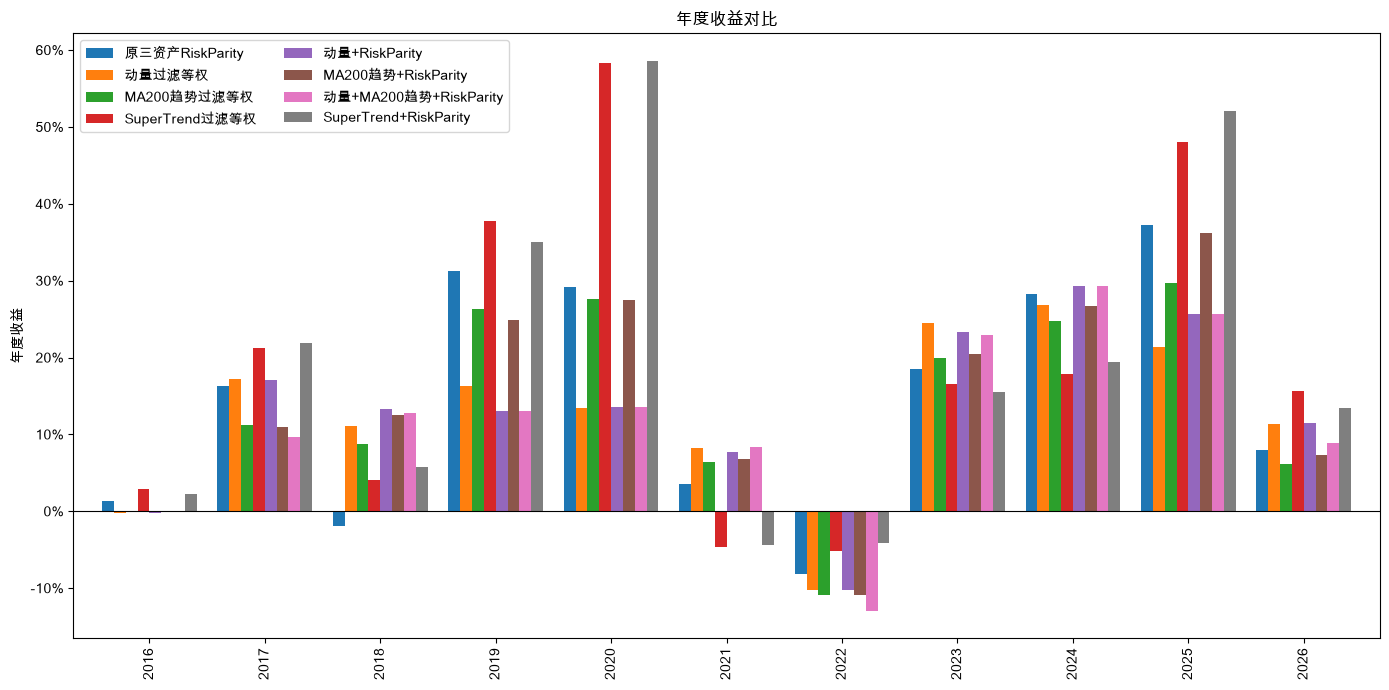

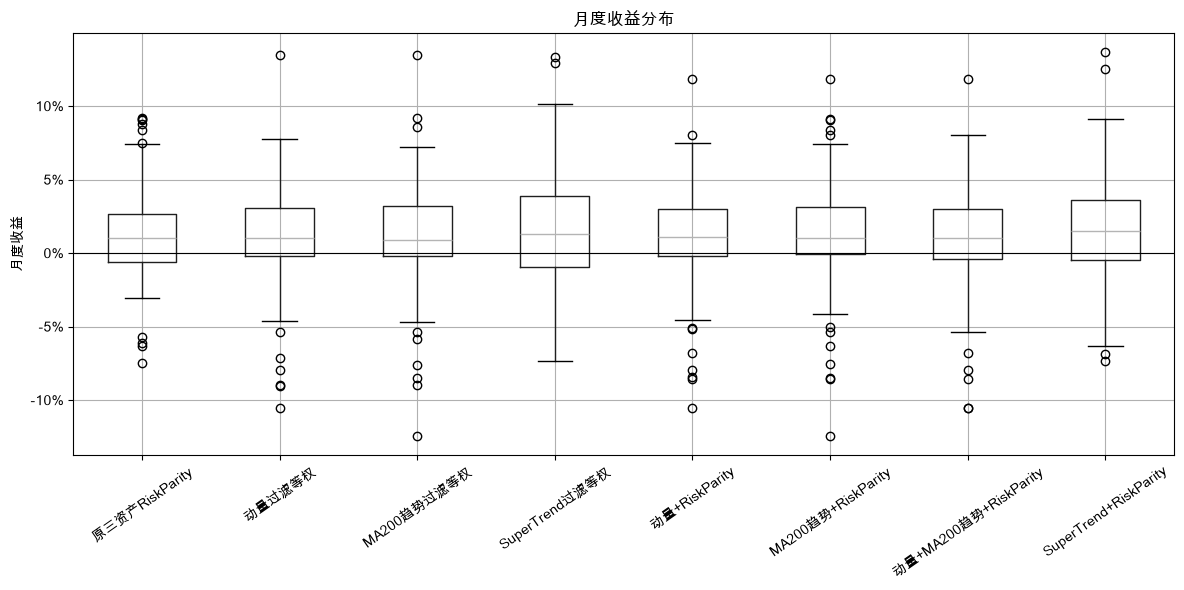

,原三资产RiskParity,动量过滤等权,MA200趋势过滤等权,SuperTrend过滤等权,动量+RiskParity,MA200趋势+RiskParity,动量+MA200趋势+RiskParity,SuperTrend+RiskParity
2016,0.0131,-0.0017,0.0000,0.0283,-0.0017,0.0000,0.0000,0.0223
2017,0.1624,0.1725,0.1119,0.2124,0.1704,0.1101,0.0965,0.2189
2018,-0.0193,0.1115,0.0870,0.0401,0.1332,0.1257,0.1275,0.0571
2019,0.3121,0.1631,0.2625,0.3773,0.1309,0.2485,0.1309,0.3505
2020,0.2911,0.1339,0.2758,0.5832,0.1352,0.2748,0.1352,0.5859
2021,0.0348,0.0824,0.0640,-0.0459,0.0765,0.0683,0.0833,-0.0440
2022,-0.0819,-0.1026,-0.1089,-0.0522,-0.1027,-0.1089,-0.1295,-0.0416
2023,0.1854,0.2455,0.1992,0.1653,0.2334,0.2045,0.2296,0.1556
2024,0.2822,0.2682,0.2477,0.1786,0.2934,0.2676,0.2934,0.1936
2025,0.3717,0.2132,0.2966,0.4808,0.2563,0.3626,0.2563,0.5203


In [9]:
annual_table = pd.DataFrame({name: annual_returns_from_nav(strat["nav"]) for name, strat in strategies.items()})
annual_table.to_csv(OUTPUT_DIR / "annual_returns.csv", encoding="utf-8-sig")

fig, ax = plt.subplots(figsize=(14, 7))
annual_table.plot(kind="bar", ax=ax, width=0.82)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("年度收益对比")
ax.set_ylabel("年度收益")
ax.yaxis.set_major_formatter(lambda x, pos: f"{x:.0%}")
ax.legend(loc="best", ncol=2)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "annual_returns.png", dpi=160)
plt.show()

monthly_returns_table = pd.DataFrame({name: monthly_returns_from_nav(strat["nav"]) for name, strat in strategies.items()})
monthly_returns_table.to_csv(OUTPUT_DIR / "monthly_returns.csv", encoding="utf-8-sig")

fig, ax = plt.subplots(figsize=(12, 6))
monthly_returns_table.boxplot(ax=ax, rot=35)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("月度收益分布")
ax.set_ylabel("月度收益")
ax.yaxis.set_major_formatter(lambda x, pos: f"{x:.0%}")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "monthly_distribution.png", dpi=160)
plt.show()

annual_table.round(4)


## 8. Drawdown Events and Underwater Curve

回撤不是只看最大值，还要看恢复时间、平均回撤深度，以及水下曲线的形状。


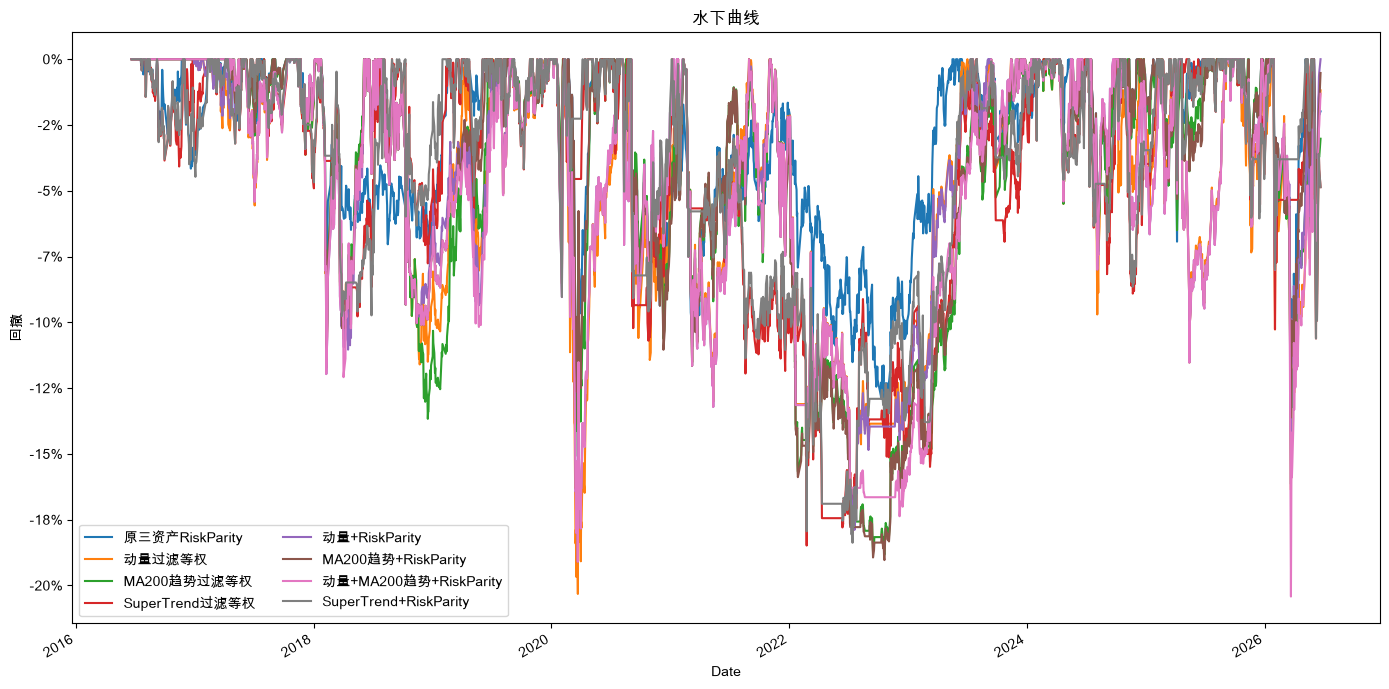

,最大回撤,平均回撤深度,平均恢复天数,最长恢复天数,回撤次数
原三资产RiskParity,-0.1353,-0.0152,12.4044,376.0,137.0
SuperTrend+RiskParity,-0.1838,-0.0174,12.9783,363.0,139.0
SuperTrend过滤等权,-0.1848,-0.0189,13.5985,509.0,138.0
MA200趋势过滤等权,-0.1883,-0.0209,15.8571,409.0,113.0
MA200趋势+RiskParity,-0.1904,-0.0214,16.4324,390.0,112.0
动量+RiskParity,-0.1909,-0.0252,21.1313,357.0,99.0
动量过滤等权,-0.2032,-0.0277,21.7253,347.0,92.0
动量+MA200趋势+RiskParity,-0.2042,-0.0279,18.2414,282.0,88.0


In [10]:
def drawdown_events(nav_s):
    dd = drawdown(nav_s).dropna()
    events = []
    in_dd = False
    start = trough = None
    trough_value = 0.0
    for date, value in dd.items():
        if not in_dd and value < 0:
            in_dd = True
            start = trough = date
            trough_value = value
        elif in_dd:
            if value < trough_value:
                trough = date
                trough_value = value
            if value >= 0:
                events.append({
                    "开始日期": pd.Timestamp(start).date(),
                    "最低点日期": pd.Timestamp(trough).date(),
                    "恢复日期": pd.Timestamp(date).date(),
                    "深度": trough_value,
                    "下跌天数": (pd.Timestamp(trough) - pd.Timestamp(start)).days,
                    "恢复天数": (pd.Timestamp(date) - pd.Timestamp(trough)).days,
                    "总持续天数": (pd.Timestamp(date) - pd.Timestamp(start)).days,
                })
                in_dd = False
                start = trough = None
                trough_value = 0.0
    if in_dd and start is not None:
        last = dd.index[-1]
        events.append({
            "开始日期": pd.Timestamp(start).date(),
            "最低点日期": pd.Timestamp(trough).date(),
            "恢复日期": "未恢复",
            "深度": trough_value,
            "下跌天数": (pd.Timestamp(trough) - pd.Timestamp(start)).days,
            "恢复天数": np.nan,
            "总持续天数": (pd.Timestamp(last) - pd.Timestamp(start)).days,
        })
    return pd.DataFrame(events).sort_values("深度") if events else pd.DataFrame()


def drawdown_summary(nav_s):
    events = drawdown_events(nav_s)
    if events.empty:
        return {"最大回撤": 0.0, "平均回撤深度": 0.0, "平均恢复天数": np.nan, "最长恢复天数": np.nan, "回撤次数": 0}
    recovered = events[pd.to_numeric(events["恢复天数"], errors="coerce").notna()].copy()
    return {
        "最大回撤": events["深度"].min(),
        "平均回撤深度": events["深度"].mean(),
        "平均恢复天数": recovered["恢复天数"].mean() if len(recovered) else np.nan,
        "最长恢复天数": recovered["恢复天数"].max() if len(recovered) else np.nan,
        "回撤次数": len(events),
    }

dd_summary = pd.DataFrame({name: drawdown_summary(strat["nav"]) for name, strat in strategies.items()}).T
dd_summary.to_csv(OUTPUT_DIR / "drawdown_summary.csv", encoding="utf-8-sig")

for name, strat in strategies.items():
    events = drawdown_events(strat["nav"])
    events.head(10).to_csv(OUTPUT_DIR / f"drawdown_events_{name}.csv", encoding="utf-8-sig", index=False)

underwater = nav.apply(drawdown)
underwater.to_csv(OUTPUT_DIR / "underwater_curves.csv", encoding="utf-8-sig")

fig, ax = plt.subplots(figsize=(14, 7))
underwater.plot(ax=ax)
ax.set_title("水下曲线")
ax.set_ylabel("回撤")
ax.yaxis.set_major_formatter(lambda x, pos: f"{x:.0%}")
ax.legend(loc="best", ncol=2)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "underwater_curves.png", dpi=160)
plt.show()

dd_summary.sort_values("最大回撤", ascending=False).round(4)


## 9. NAV and Weight Charts

净值曲线看历史表现，权重曲线看策略是否有可解释的资产暴露。


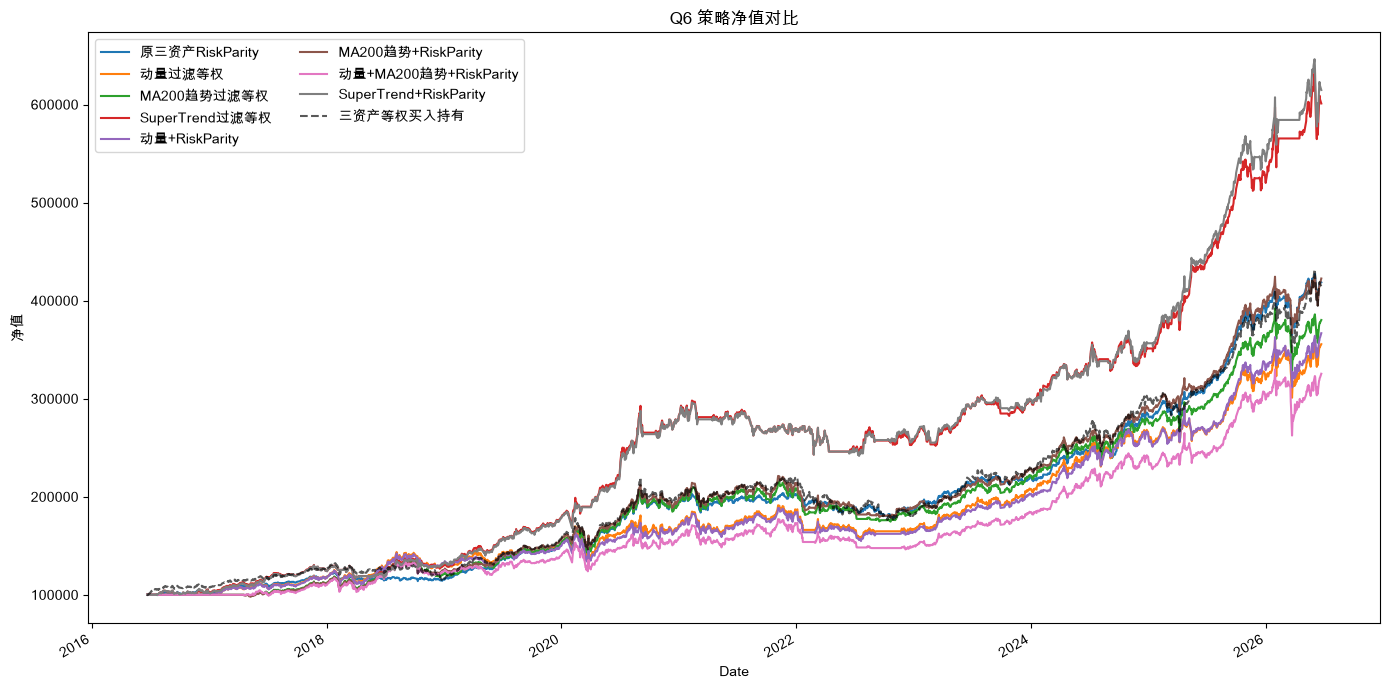

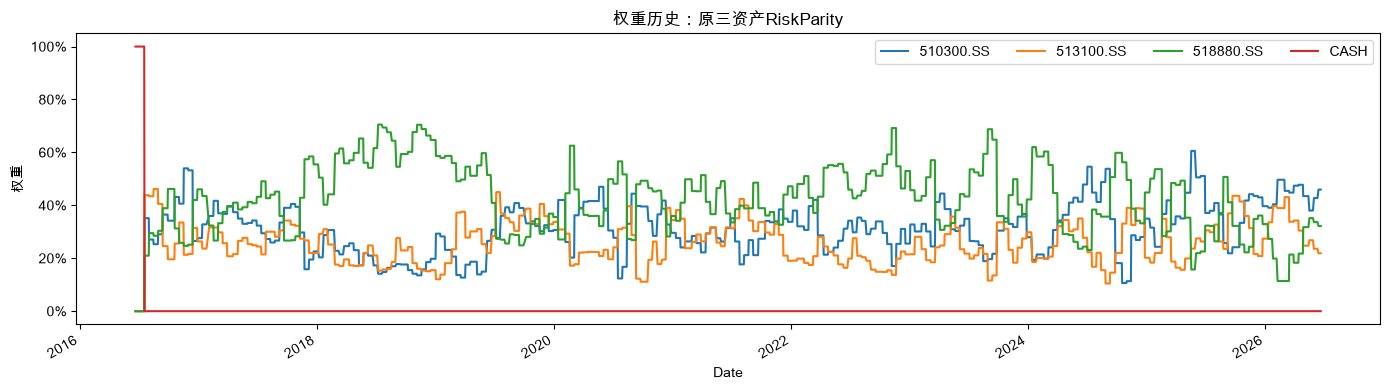

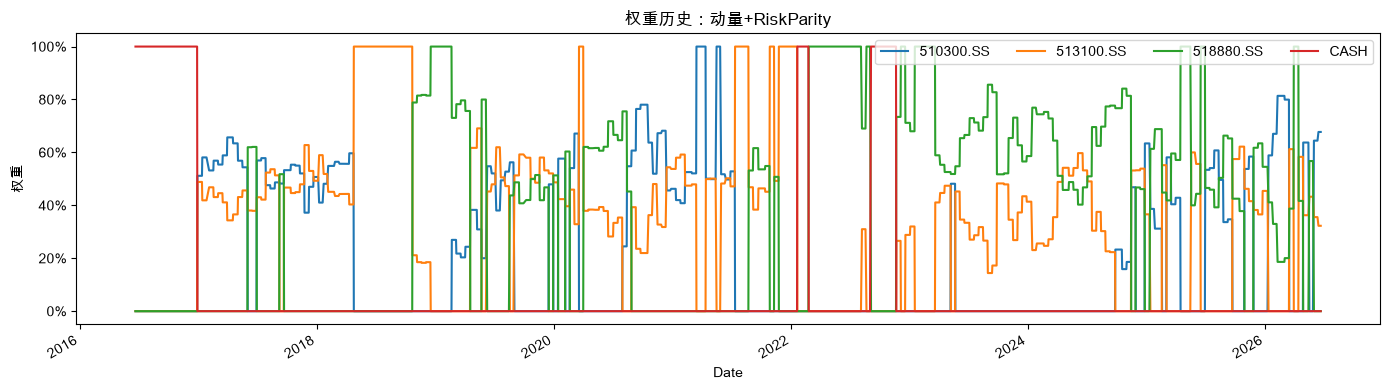

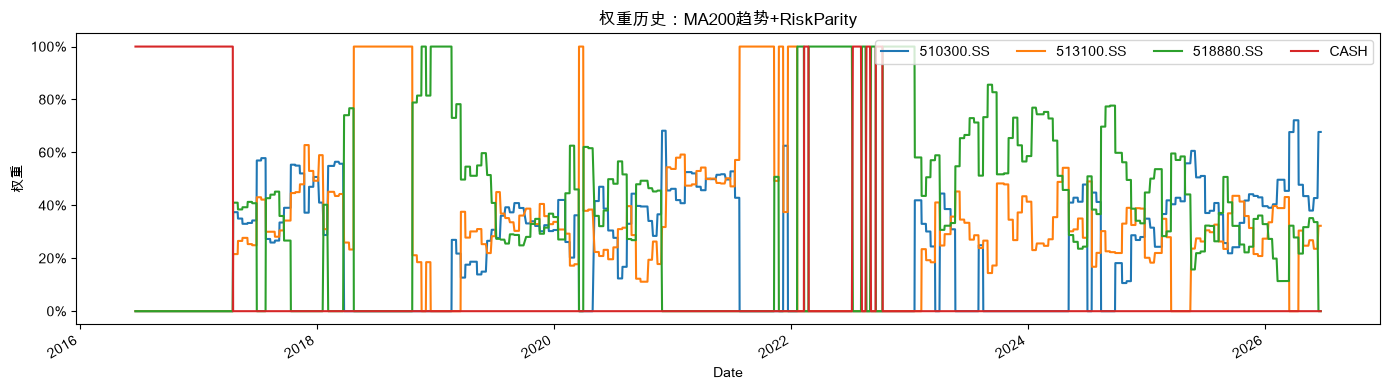

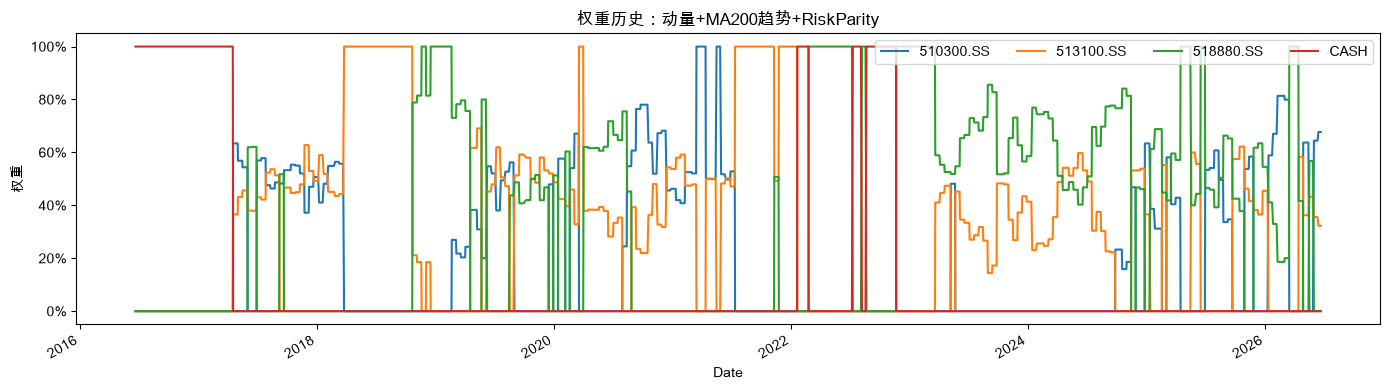

In [11]:
fig, ax = plt.subplots(figsize=(14, 7))
nav.plot(ax=ax)
benchmark_buy_hold.plot(ax=ax, color="black", linestyle="--", alpha=0.65, label="三资产等权买入持有")
ax.set_title("Q6 策略净值对比")
ax.set_ylabel("净值")
ax.legend(loc="best", ncol=2)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "nav_comparison.png", dpi=160)
plt.show()

for name in ["原三资产RiskParity", "动量+RiskParity", "MA200趋势+RiskParity", "动量+MA200趋势+RiskParity"]:
    fig, ax = plt.subplots(figsize=(14, 4))
    weights_by_strategy[name].plot(ax=ax)
    ax.set_title(f"权重历史：{name}")
    ax.set_ylabel("权重")
    ax.yaxis.set_major_formatter(lambda x, pos: f"{x:.0%}")
    ax.legend(loc="best", ncol=4)
    fig.tight_layout()
    safe_name = name.replace("+", "_").replace(" ", "_")
    fig.savefig(OUTPUT_DIR / f"weights_{safe_name}.png", dpi=160)
    plt.show()


## 10. Parameter Sensitivity

敏感性检查用小网格，目标是看结果形状，而不是寻找最漂亮的历史参数。


In [12]:
def sensitivity_metric_row(name, strat):
    row = strategy_metrics(strat["nav"], strat["returns"])
    row["策略"] = name
    row["平均现金"] = strat["weights"]["CASH"].mean()
    return row

# RiskParity volatility window sensitivity
vol_rows = []
for vol_window in [10, 20, 30, 40, 60]:
    strat = run_strategy(f"RP_vol{vol_window}", all_assets_selector, rp_allocator(vol_window))
    row = sensitivity_metric_row(strat["name"], strat)
    row["vol_window"] = vol_window
    vol_rows.append(row)
rp_vol_sensitivity = pd.DataFrame(vol_rows).set_index("vol_window")
rp_vol_sensitivity.to_csv(OUTPUT_DIR / "sensitivity_riskparity_vol_window.csv", encoding="utf-8-sig")

# Momentum lookback and Top-N sensitivity, using Momentum + RiskParity as the main layered variant.
mom_rows = []
for lookback in [63, 126, 252]:
    for top_n in [1, 2, 3]:
        strat = run_strategy(
            f"MOM{lookback}_top{top_n}_RP",
            momentum_selector(lookback=lookback, top_n=top_n),
            rp_allocator(BASE_VOL_WINDOW),
        )
        row = sensitivity_metric_row(strat["name"], strat)
        row["lookback"] = lookback
        row["top_n"] = top_n
        mom_rows.append(row)
momentum_sensitivity = pd.DataFrame(mom_rows).set_index(["lookback", "top_n"])
momentum_sensitivity.to_csv(OUTPUT_DIR / "sensitivity_momentum_topn.csv", encoding="utf-8-sig")

# MA trend window sensitivity, using Trend + RiskParity.
ma_rows = []
for ma_window in [100, 150, 200, 250]:
    strat = run_strategy(
        f"MA{ma_window}_RP",
        ma_trend_selector(ma_window),
        rp_allocator(BASE_VOL_WINDOW),
    )
    row = sensitivity_metric_row(strat["name"], strat)
    row["ma_window"] = ma_window
    ma_rows.append(row)
ma_sensitivity = pd.DataFrame(ma_rows).set_index("ma_window")
ma_sensitivity.to_csv(OUTPUT_DIR / "sensitivity_ma_trend_window.csv", encoding="utf-8-sig")

# SuperTrend sensitivity, because H/L/C data is available in the current environment.
st_rows = []
for atr_period in [7, 10, 14]:
    for multiplier in [2.0, 3.0, 4.0]:
        strat = run_strategy(
            f"ST{atr_period}_{multiplier:g}_RP",
            supertrend_selector(atr_period, multiplier),
            rp_allocator(BASE_VOL_WINDOW),
        )
        row = sensitivity_metric_row(strat["name"], strat)
        row["atr_period"] = atr_period
        row["multiplier"] = multiplier
        st_rows.append(row)
supertrend_sensitivity = pd.DataFrame(st_rows).set_index(["atr_period", "multiplier"])
supertrend_sensitivity.to_csv(OUTPUT_DIR / "sensitivity_supertrend.csv", encoding="utf-8-sig")

print("RiskParity vol window sensitivity")
display(rp_vol_sensitivity[["累计收益", "年化收益", "最大回撤", "夏普", "卡玛", "平均现金"]].round(4))
print("Momentum sensitivity")
display(momentum_sensitivity[["累计收益", "年化收益", "最大回撤", "夏普", "卡玛", "平均现金"]].round(4))
print("MA trend sensitivity")
display(ma_sensitivity[["累计收益", "年化收益", "最大回撤", "夏普", "卡玛", "平均现金"]].round(4))
print("SuperTrend sensitivity")
display(supertrend_sensitivity[["累计收益", "年化收益", "最大回撤", "夏普", "卡玛", "平均现金"]].round(4))


RiskParity vol window sensitivity


,累计收益,年化收益,最大回撤,夏普,卡玛,平均现金
vol_window,,,,,,
10,3.5559,0.1708,-0.1368,1.4585,1.2483,0.0041
20,3.1864,0.1605,-0.1353,1.3863,1.1862,0.0082
30,3.3344,0.1647,-0.1327,1.4117,1.2413,0.0124
40,3.3059,0.1639,-0.1428,1.3927,1.1477,0.0165
60,3.2212,0.1615,-0.1481,1.3709,1.0903,0.0247


Momentum sensitivity


累计收益    年化收益    最大回撤      夏普      卡玛    平均现金
lookback top_n                                                
63       1      1.3692  0.0938 -0.3845  0.5310  0.2440  0.0495
         2      2.9999  0.1550 -0.2514  1.0373  0.6166  0.0495
         3      3.7291  0.1753 -0.2425  1.2244  0.7229  0.0495
126      1      1.5901  0.1040 -0.2857  0.5851  0.3640  0.0825
         2      2.6679  0.1447 -0.1909  0.9754  0.7576  0.0825
         3      3.2896  0.1634 -0.1789  1.1891  0.9137  0.0825
252      1      1.9524  0.1191 -0.4157  0.6409  0.2866  0.1113
         2      3.2488  0.1623 -0.2089  1.0890  0.7769  0.1113
         3      2.6164  0.1430 -0.2089  1.0843  0.6845  0.1113

MA trend sensitivity


,累计收益,年化收益,最大回撤,夏普,卡玛,平均现金
ma_window,,,,,,
100,2.6461,0.1440,-0.2967,1.0320,0.4851,0.0660
150,2.8587,0.1507,-0.2094,1.1273,0.7198,0.0907
200,3.2256,0.1616,-0.1904,1.2109,0.8491,0.1031
250,3.1286,0.1588,-0.1872,1.1969,0.8484,0.1155


SuperTrend sensitivity


累计收益    年化收益    最大回撤      夏普      卡玛    平均现金
atr_period multiplier                                                
7          2.0         3.1619  0.1598 -0.1621  1.1769  0.9856  0.1237
           3.0         5.0635  0.2061 -0.1805  1.4469  1.1418  0.1155
           4.0         3.0859  0.1576 -0.1696  1.1419  0.9294  0.0866
10         2.0         3.9836  0.1817 -0.1589  1.2936  1.1434  0.0990
           3.0         5.1478  0.2078 -0.1838  1.4683  1.1308  0.1237
           4.0         3.9775  0.1816 -0.2234  1.2811  0.8128  0.0948
14         2.0         4.2262  0.1876 -0.1589  1.3370  1.1803  0.0990
           3.0         4.3213  0.1898 -0.2361  1.3074  0.8040  0.0969
           4.0         2.9464  0.1534 -0.2485  1.0673  0.6174  0.0866

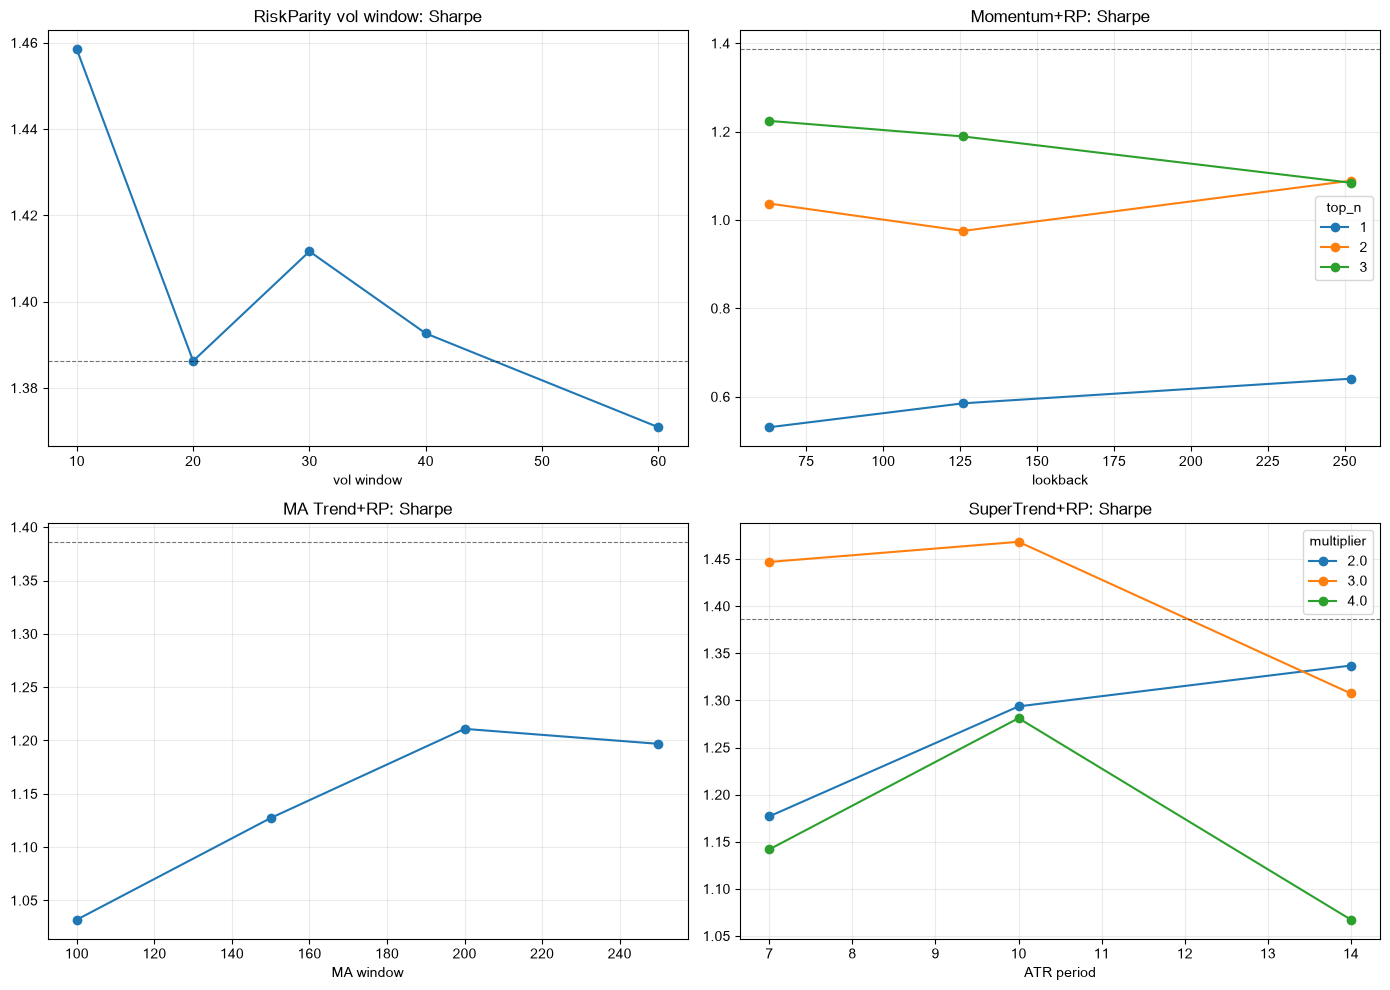

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

rp_vol_sensitivity["夏普"].plot(marker="o", ax=axes[0, 0], title="RiskParity vol window: Sharpe")
axes[0, 0].set_xlabel("vol window")

momentum_sensitivity.reset_index().pivot(index="lookback", columns="top_n", values="夏普").plot(marker="o", ax=axes[0, 1], title="Momentum+RP: Sharpe")
axes[0, 1].set_xlabel("lookback")

ma_sensitivity["夏普"].plot(marker="o", ax=axes[1, 0], title="MA Trend+RP: Sharpe")
axes[1, 0].set_xlabel("MA window")

supertrend_sensitivity.reset_index().pivot(index="atr_period", columns="multiplier", values="夏普").plot(marker="o", ax=axes[1, 1], title="SuperTrend+RP: Sharpe")
axes[1, 1].set_xlabel("ATR period")

for ax in axes.ravel():
    ax.axhline(q3_metrics.loc["原三资产RiskParity", "夏普"], color="black", linestyle="--", linewidth=0.8, alpha=0.55)
    ax.grid(True, alpha=0.25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "sensitivity_summary.png", dpi=160)
plt.show()


## 11. Plain-Language Conclusion

下面的代码自动提取历史收益、风险调整收益和结构平衡候选。最终文字结论仍要结合样本期偏差、现金暴露、参数敏感性和未来失效场景判断。


In [14]:
historical_best = q5_metrics["累计收益"].idxmax()
risk_adjusted_best = q5_metrics["夏普"].idxmax()
calmar_best = q5_metrics["卡玛"].idxmax()
lowest_drawdown = q5_metrics["最大回撤"].idxmax()  # drawdown is negative; larger is shallower

summary = pd.Series({
    "样本开始": str(close.index[0].date()),
    "样本结束": str(close.index[-1].date()),
    "历史收益最高": historical_best,
    "夏普最高": risk_adjusted_best,
    "卡玛最高": calmar_best,
    "最大回撤最浅": lowest_drawdown,
    "RP基准累计收益": q5_metrics.loc["原三资产RiskParity", "累计收益"],
    "RP基准最大回撤": q5_metrics.loc["原三资产RiskParity", "最大回撤"],
    "RP基准夏普": q5_metrics.loc["原三资产RiskParity", "夏普"],
})
summary.to_csv(OUTPUT_DIR / "research_summary.csv", encoding="utf-8-sig")
summary


样本开始                   2016-06-21
样本结束                   2026-06-22
历史收益最高      SuperTrend+RiskParity
夏普最高        SuperTrend+RiskParity
卡玛最高               原三资产RiskParity
最大回撤最浅             原三资产RiskParity
RP基准累计收益                 3.186387
RP基准最大回撤                -0.135315
RP基准夏普                   1.386273
dtype: object

### 结论模板

- Historical best:
- Risk-adjusted best:
- Most structurally balanced:
- Main sample-period advantage:
- Main future failure mode:
- What to test next:
